# Patch Size in a Small Vision Transformer

**Samuel Collins** - Ph.D. Student, Department of Cyber-Physical Systems,
Clark Atlanta University

Computer Vision, Lab Assignment 6. Instructor: Dr. Kishor Datta Gupta.

A two-block ViT trained from scratch on a 10,000-image CIFAR-10 subset, once
with 4x4 patches and once with 8x8 patches, everything else identical.

This notebook is a thin wrapper over the `vit_patch_size` package in `src/`.
It retrains both models live with the same function `run_experiment.py` uses,
then checks the outcome against the saved `results/*.json` that the report is
built from. The written analysis is `report/ViT_Patch_Size_Report.pdf`.

## 1. Setup and configuration

In [1]:
import json
import sys
from dataclasses import fields
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display

from vit_patch_size import CLASSES, COMPARED_FIELDS, RunConfig, data, plots, resolve_device
from vit_patch_size import env, train
from vit_patch_size.model import ViT, attention_entries, count_parameters

base = RunConfig()
configs = {"p4": base, "p8": base.with_patch(8)}
device = resolve_device()

print("hardware:", env.hardware(device))
print("software:", env.software())
for f in COMPARED_FIELDS:
    print(f"  {f:<18} {getattr(base, f)}")
differing = [f.name for f in fields(base)
             if getattr(configs['p4'], f.name) != getattr(configs['p8'], f.name)]
print("fields that differ between the two runs:", differing)

hardware: {'chip': 'Apple M4 Max', 'platform': 'macOS-26.6.2-arm64-arm-64bit', 'device': 'mps', 'mps_available': True, 'cuda_available': False}
software: {'python': '3.12.13', 'torch': '2.14.0', 'torchvision': '0.29.0', 'numpy': '2.5.3'}
  seed               42
  n_train            10000
  n_val              2000
  embed_dim          64
  depth              2
  heads              4
  mlp_dim            128
  dropout            0.1
  lr                 0.0003
  betas              (0.9, 0.999)
  weight_decay       0.0
  batch_size         64
  epochs             5
  n_fixed_examples   8
fields that differ between the two runs: ['name', 'patch_size']


## 2. The data

A stratified 10,000-image training subset and a disjoint 2,000-image
validation subset, both from CIFAR-10's official *training* split. The test
split is never loaded. Indices, seed and a checksum are committed in
`data/split_indices.json`; the images are not.

In [2]:
split = data.load_split(base)
m = split["manifest"]
print(f"train {len(split['y_train']):,}  val {len(split['y_val']):,}  seed {m['seed']}")
print(f"checksum {m['checksum'][:16]}...  test split used: {m['test_split_used']}")
print("train per class", m["train_per_class"])
print("val per class  ", m["val_per_class"])
print("channel mean", [round(v, 4) for v in m["mean"]], " std", [round(v, 4) for v in m["std"]])
print("input tensor", tuple(split["x_train"].shape), "dtype", split["x_train"].dtype)

train 10,000  val 2,000  seed 42
checksum 0a7a9f92ecec1aac...  test split used: False
train per class [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
val per class   [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
channel mean [0.4915, 0.4817, 0.4465]  std [0.248, 0.2447, 0.2626]
input tensor (10000, 3, 32, 32) dtype torch.float32


### Sixteen labeled examples

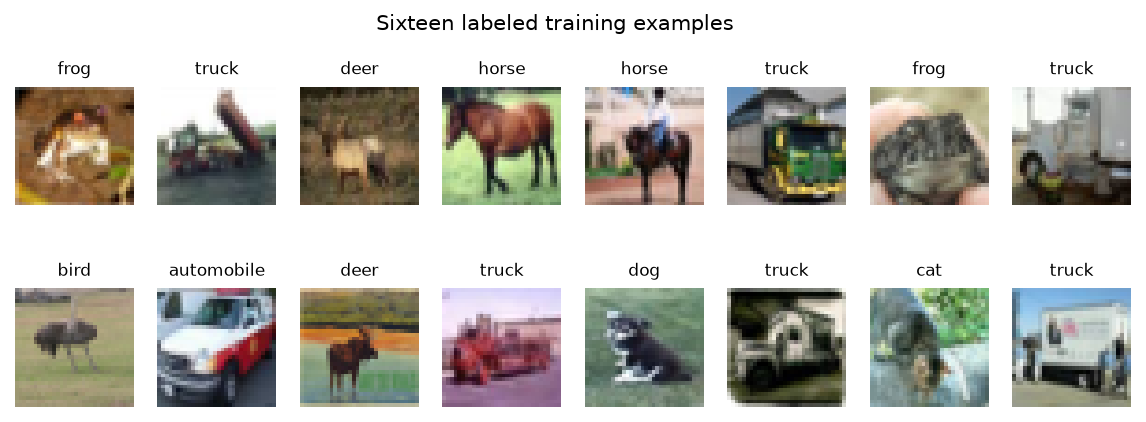

In [3]:
out = Path("plots/notebook"); out.mkdir(parents=True, exist_ok=True)
plots.sample_grid(split["raw_train"], split["y_train"].tolist(), out / "samples.png")
display(Image(filename=out / "samples.png"))

## 3. The model

Written out by hand in `src/vit_patch_size/model.py` rather than built from
`nn.TransformerEncoderLayer`, because the report needs the attention weights
themselves. No code was copied from another repository: the structure follows
Dosovitskiy et al. (ICLR 2021) and Vaswani et al. (NeurIPS 2017).
`nn.MultiheadAttention` is used only in `tests/test_model.py`, as an oracle
that the hand-written attention must match given the same weights.

Specification, as the brief fixes it: 4x4 (then 8x8) non-overlapping patches,
one shared linear projection to width 64, a learnable class token, learned
position embeddings, two pre-norm encoder blocks with layer normalization and
residual connections, four heads, feed-forward width 128, and a linear head
producing 10 logits.

In [4]:
import inspect
from vit_patch_size import model as vit_model

for obj in (vit_model.patchify, vit_model.Attention, vit_model.Block, vit_model.ViT):
    print(inspect.getsource(obj))

def patchify(x: torch.Tensor, patch_size: int) -> torch.Tensor:
    """(B, C, H, W) -> (B, N, C*P*P), non-overlapping patches in raster order."""
    b, c, h, w = x.shape
    p = patch_size
    if h % p or w % p:
        raise ValueError(f"{h}x{w} image is not divisible by patch size {p}")
    x = x.reshape(b, c, h // p, p, w // p, p)
    x = x.permute(0, 2, 4, 1, 3, 5)               # (B, h/p, w/p, C, P, P)
    return x.reshape(b, (h // p) * (w // p), c * p * p)

class Attention(nn.Module):
    """Multi-head self-attention with no mask.

    Per head: scores = Q K^T / sqrt(d_head), weights = softmax(scores) along
    the key axis, output = weights V. The heads are concatenated and mixed
    by an output projection.
    """

    def __init__(self, dim: int, heads: int, dropout: float):
        super().__init__()
        if dim % heads:
            raise ValueError("embedding width must be divisible by heads")
        self.heads, self.head_dim = heads, dim // heads
        self.qkv = nn

## 3.1 Tensor shapes

Shapes come from a real forward pass (`trace_shapes`), not from arithmetic.
With P x P patches on a 32 x 32 image, N = (32/P)^2 patch tokens and
L = N + 1 tokens including the class token.

In [5]:
rows = []
for name, cfg in configs.items():
    model = train.build_model(cfg)
    trace = model.trace_shapes(batch_size=64)
    print(f"{cfg.patch_size}x{cfg.patch_size}: N = (32/{cfg.patch_size})^2 = {cfg.num_patches}, "
          f"L = N + 1 = {cfg.tokens}, parameters = {count_parameters(model):,}")
    for stage, shp in trace.items():
        print(f"    {stage:<26} {shp}")
    print("    parameter breakdown:", model.parameter_breakdown())
    print()

4x4: N = (32/4)^2 = 64, L = N + 1 = 65, parameters = 75,082
    images                     (64, 3, 32, 32)
    patches                    (64, 64, 48)
    projected_tokens           (64, 64, 64)
    with_class_token           (64, 65, 64)
    with_position_embedding    (64, 65, 64)
    encoder_output             (64, 65, 64)
    class_representation       (64, 64)
    logits                     (64, 10)
    parameter breakdown: {'patch_projection': 3136, 'class_token': 64, 'position_embedding': 4160, 'encoder_blocks': 66944, 'final_norm_and_head': 778}

8x8: N = (32/8)^2 = 16, L = N + 1 = 17, parameters = 81,226
    images                     (64, 3, 32, 32)
    patches                    (64, 16, 192)
    projected_tokens           (64, 16, 64)
    with_class_token           (64, 17, 64)
    with_position_embedding    (64, 17, 64)
    encoder_output             (64, 17, 64)
    class_representation       (64, 64)
    logits                     (64, 10)
    parameter breakdown: {'patch

## 3.2 How attention works

Each token `t` is multiplied by three learned matrices to give a **query**
`q = W_Q t`, a **key** `k = W_K t` and a **value** `v = W_V t`.

- **Queries and keys decide the weights.** The score of token *i* for token
  *j* is the dot product `q_i . k_j`, a similarity. Scores are divided by
  `sqrt(d_key)` for stable gradients and passed through a softmax along *j*,
  giving non-negative weights that sum to 1.
- **Values produce the output.** The output for token *i* is the
  weight-weighted sum of every token's value vector.
- Four heads repeat this in four 16-dimensional subspaces; an output
  projection mixes them.

**Why positional information is needed.** Attention weights depend only on
token content, so without positions the patches are an unordered set and
shuffling an image's patches cannot change the output. The learned position
embedding is what lets the model use where a patch is. The cell below shows
both halves of this on the real model.

**Why there is no causal mask.** Classification has no generation order.
Every patch should attend to every patch in both directions. A causal mask
(future positions set to minus infinity before the softmax) belongs to the
transformer decoder; a ViT is encoder-only. With one, the class token at
position 0 could see nothing but itself.

### Queries, keys, values: one worked example

Three value vectors and the query-1 scores `[2, 4, 4]` from the lecture
example, with exact softmax. The lecture slide rounds the weights to
`[0, 0.5, 0.5]`; the second row divides scores by sqrt(3), as the model does.

In [6]:
import math
values = torch.tensor([[0., 0., 0.], [1., 4., 0.], [1., 3., 1.5]])
scores = torch.tensor([2., 4., 4.])
for label, s in (("raw scores", scores), ("scores / sqrt(3)", scores / math.sqrt(3))):
    w = s.softmax(0)
    print(f"{label:<18} weights {[round(x, 4) for x in w.tolist()]}  ->  "
          f"sum_i w_i v_i = {[round(x, 3) for x in (w @ values).tolist()]}")

raw scores         weights [0.0634, 0.4683, 0.4683]  ->  sum_i w_i v_i = [0.937, 3.278, 0.702]
scores / sqrt(3)   weights [0.1361, 0.4319, 0.4319]  ->  sum_i w_i v_i = [0.864, 3.024, 0.648]


### Attention is global and unmasked

Every token attends to every token; the class token (position 0) puts
non-zero weight on later positions, which a causal mask would forbid.

In [7]:
model = train.build_model(configs["p8"]).eval()
x = split["x_val"][:4]
with torch.no_grad():
    logits, maps = model(x, return_attn=True)
w = maps[0]
print("attention tensor (batch, heads, L, L):", tuple(w.shape))
print("rows sum to 1:", bool(torch.allclose(w.sum(-1), torch.ones_like(w.sum(-1)), atol=1e-5)))
print("weight above the diagonal (a causal mask would make this 0):", float(torch.triu(w, 1).sum()))
print("logits shape:", tuple(logits.shape), "- raw logits; CrossEntropyLoss applies log-softmax itself")

attention tensor (batch, heads, L, L): (4, 4, 17, 17)
rows sum to 1: True
weight above the diagonal (a causal mask would make this 0): 127.97855377197266
logits shape: (4, 10) - raw logits; CrossEntropyLoss applies log-softmax itself


### Position embeddings: shuffle the patches

In [8]:
p = 8
model = train.build_model(configs["p8"]).eval()
x = split["x_val"][:1]
g = p and 32 // p
perm = torch.randperm(g * g, generator=torch.Generator().manual_seed(0))
blocks = x.reshape(1, 3, g, p, g, p).permute(0, 1, 2, 4, 3, 5).reshape(1, 3, g * g, p, p)[:, :, perm]
shuffled = blocks.reshape(1, 3, g, g, p, p).permute(0, 1, 2, 4, 3, 5).reshape(1, 3, 32, 32)

with torch.no_grad():
    with_pos = (model(x) - model(shuffled)).abs().max().item()
    model.pos_embed.zero_()
    without_pos = (model(x) - model(shuffled)).abs().max().item()
print("(untrained model with its initial position embedding, std 0.02, so the effect is small")
print(" but clearly non-zero; training makes the embedding larger and more structured)")
print(f"largest logit change when the 16 patches are shuffled, with position embedding:    {with_pos:.4f}")
print(f"largest logit change when the 16 patches are shuffled, position embedding zeroed:  {without_pos:.2e}")

(untrained model with its initial position embedding, std 0.02, so the effect is small
 but clearly non-zero; training makes the embedding larger and more structured)
largest logit change when the 16 patches are shuffled, with position embedding:    0.0030
largest logit change when the 16 patches are shuffled, position embedding zeroed:  7.45e-08


## 4. Train both models from scratch

Adam, learning rate 3e-4, batch size 64, five epochs, the brief's starting
configuration. Validation runs with dropout off and no gradient updates.

In [9]:
results = {name: train.run(cfg, split) for name, cfg in configs.items()}

[p4] P=4 N=64 L=65 params=75,082 device=mps


[p4] epoch 1/5 train 2.0622/0.2480  val 1.9839/0.2610  1.4s


[p4] epoch 2/5 train 1.8926/0.3015  val 1.8153/0.3205  1.0s


[p4] epoch 3/5 train 1.7826/0.3403  val 1.7260/0.3635  0.9s


[p4] epoch 4/5 train 1.7090/0.3623  val 1.6969/0.3680  1.0s


...

[p8] epoch 1/5 train 2.0653/0.2366  val 2.0104/0.2625  1.2s


[p8] epoch 2/5 train 1.9419/0.2885  val 1.8997/0.2980  1.1s


[p8] epoch 3/5 train 1.8649/0.3157  val 1.8327/0.3295  1.0s


[p8] epoch 4/5 train 1.8052/0.3406  val 1.7820/0.3350  1.1s


[p8] epoch 5/5 train 1.7656/0.3561  val 1.7584/0.3480  1.1s


### Do the saved results reproduce?

`results/p4.json` and `results/p8.json` are what the report is built from.
Here, the live run is compared with them field by field.

In [10]:
for name, live in results.items():
    saved = json.loads(Path(f"results/{name}.json").read_text())
    diffs = {k: max(abs(a[k] - b[k]) for a, b in zip(live["history"], saved["history"]))
             for k in ("train_loss", "train_acc", "val_loss", "val_acc")}
    same_preds = live["val_preds"] == saved["val_preds"]
    print(f"{name}: max |live - saved| per metric {diffs}; predictions identical: {same_preds}")
    print(f"      runtime live {live['total_seconds']:.1f} s vs saved {saved['total_seconds']:.1f} s "
          f"(wall-clock varies run to run; metrics do not)")

p4: max |live - saved| per metric {'train_loss': 0.0, 'train_acc': 0.0, 'val_loss': 0.0, 'val_acc': 0.0}; predictions identical: True
      runtime live 5.3 s vs saved 5.1 s (wall-clock varies run to run; metrics do not)
p8: max |live - saved| per metric {'train_loss': 0.0, 'train_acc': 0.0, 'val_loss': 0.0, 'val_acc': 0.0}; predictions identical: True
      runtime live 5.4 s vs saved 5.4 s (wall-clock varies run to run; metrics do not)


### Learning curves, one model at a time

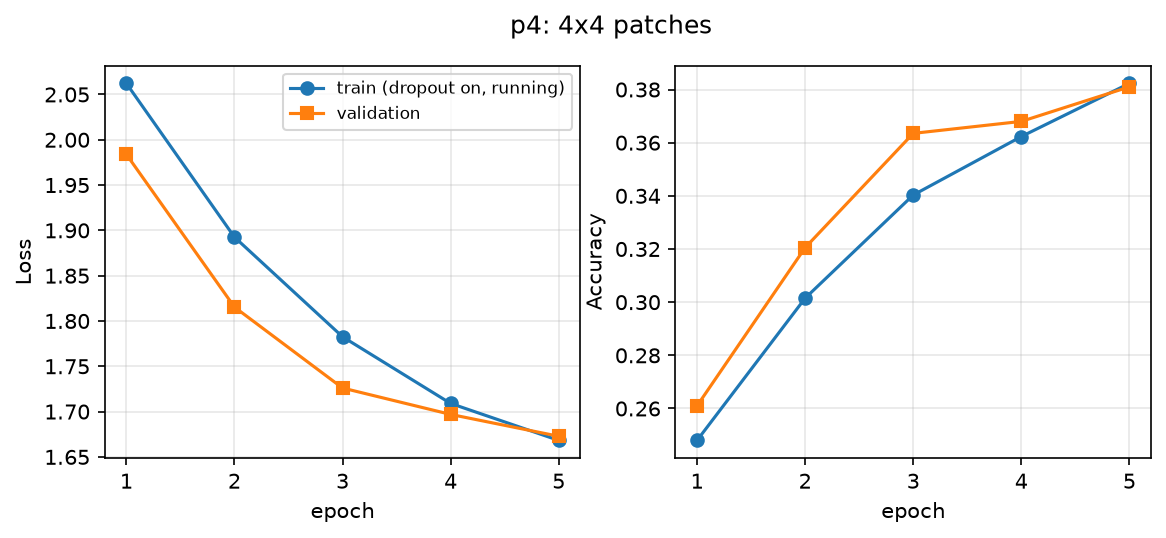

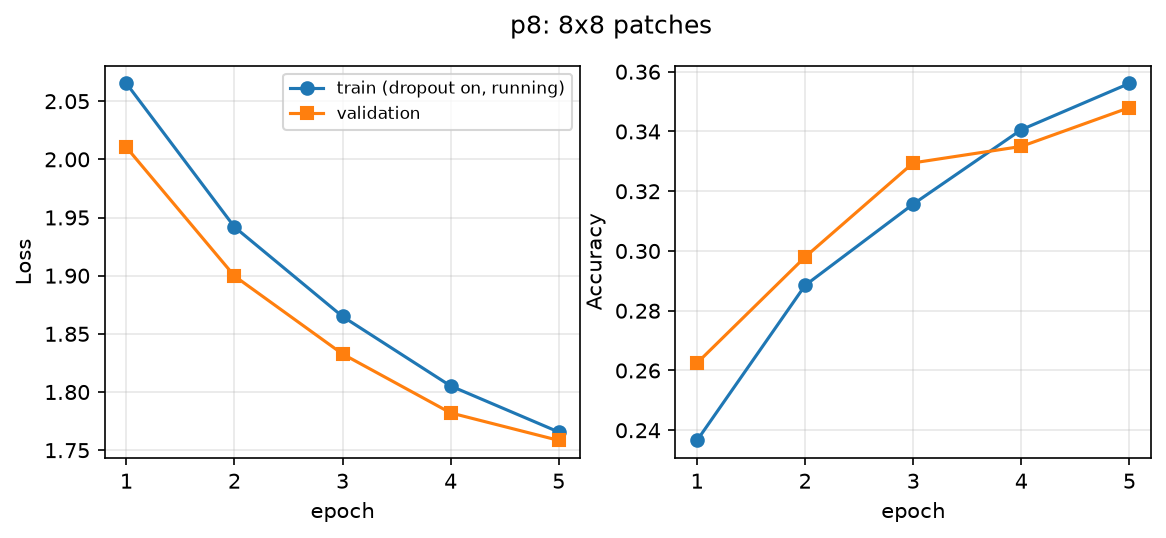

In [11]:
for name, run in results.items():
    plots.learning_curves(run, name, out / f"{name}_curves.png")
    display(Image(filename=out / f"{name}_curves.png"))

### Eight fixed validation examples, both models

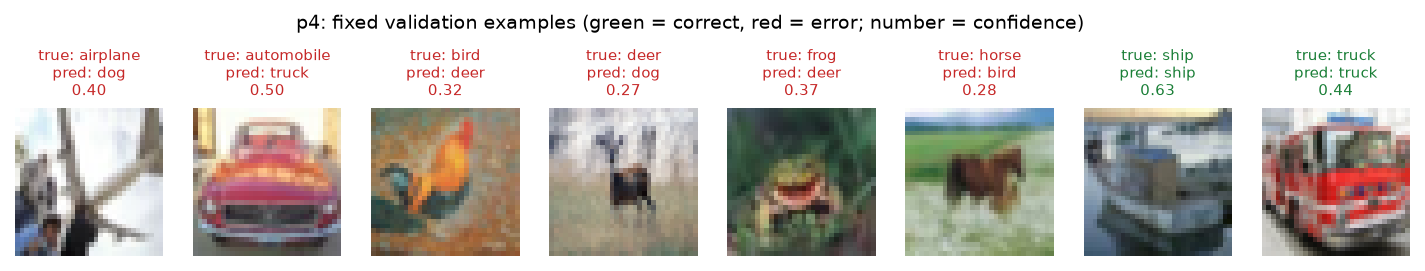

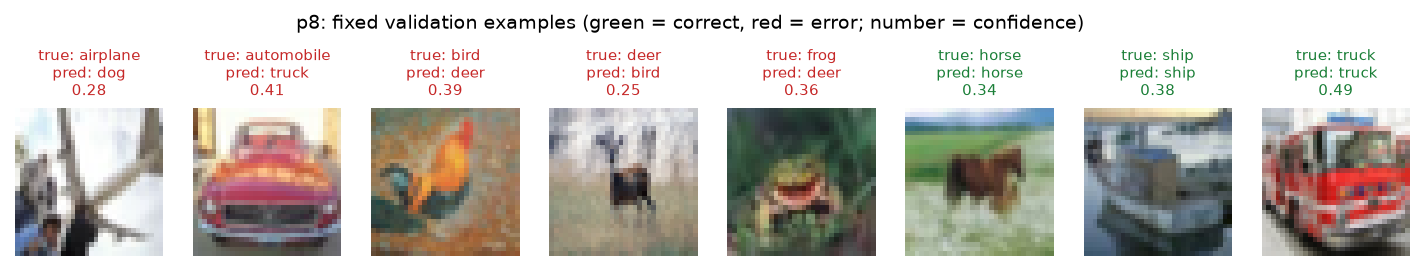

         true 4x4 predicted 8x8 predicted
0    airplane           dog           dog
1  automobile         truck         truck
2        bird          deer          deer
3        deer           dog          bird
4        frog          deer          deer
5       horse          bird         horse
6        ship          ship          ship
7       truck         truck         truck


In [12]:
for name, run in results.items():
    plots.predictions_panel(run, split["raw_val"], out / f"{name}_predictions.png")
    display(Image(filename=out / f"{name}_predictions.png"))
print(pd.DataFrame({
    "true": [e["true"] for e in results["p4"]["fixed_examples"]],
    "4x4 predicted": [e["pred"] for e in results["p4"]["fixed_examples"]],
    "8x8 predicted": [e["pred"] for e in results["p8"]["fixed_examples"]],
}).to_string())

## 5. The controlled comparison

Same split, seed, preprocessing, width, depth, heads, feed-forward width,
optimizer settings, batch size and epoch budget. Only the patch size differs.

,patch,N,L,L^2 entries/head/layer,parameters,val acc,val loss,train acc (eval mode),runtime (s)
0,4x4,64,65,4225,75082,0.381,1.6728,0.4027,5.3
1,8x8,16,17,289,81226,0.348,1.7584,0.3853,5.4


attention-score entries, 4x4 / 8x8 = 14.6x; runtime ratio = 0.98x


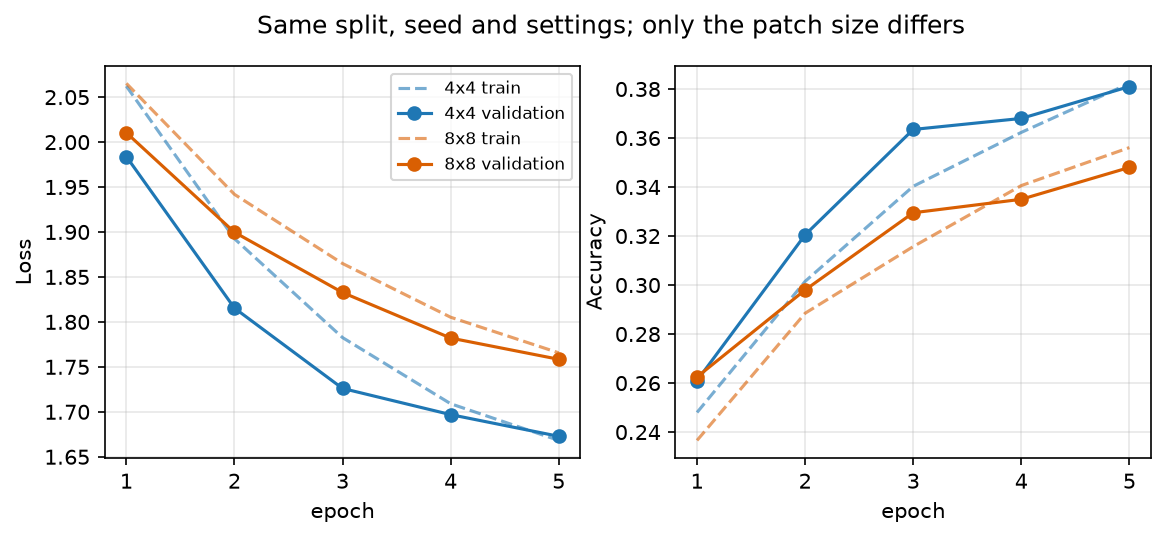

In [13]:
table = pd.DataFrame([{
    "patch": f"{r['config']['patch_size']}x{r['config']['patch_size']}",
    "N": r["model"]["num_patches"], "L": r["model"]["tokens"],
    "L^2 entries/head/layer": r["model"]["attn_entries"],
    "parameters": r["model"]["parameters"],
    "val acc": round(r["final_val_acc"], 4), "val loss": round(r["final_val_loss"], 4),
    "train acc (eval mode)": round(r["history"][-1]["train_eval_acc"], 4),
    "runtime (s)": round(r["total_seconds"], 1),
} for r in results.values()])
display(table)
ratio = table["L^2 entries/head/layer"][0] / table["L^2 entries/head/layer"][1]
print(f"attention-score entries, 4x4 / 8x8 = {ratio:.1f}x; runtime ratio = "
      f"{results['p4']['total_seconds'] / results['p8']['total_seconds']:.2f}x")
plots.comparison_curves(results, out / "comparison.png")
display(Image(filename=out / "comparison.png"))

## 6. Supplementary evidence (saved by `scripts/run_supplementary.py` and `scripts/run_timing.py`)

Read from files rather than recomputed here: five seeds on the same split,
and per-step timing on CPU and the GPU.

In [14]:
seeds = json.loads(Path("results/supplementary/seed_replication.json").read_text())["by_run"]
df = pd.DataFrame({"seed": seeds["p4"]["seeds"], "4x4 val acc": seeds["p4"]["val_acc"],
                   "8x8 val acc": seeds["p8"]["val_acc"]})
df["4x4 - 8x8 (points)"] = (100 * (df["4x4 val acc"] - df["8x8 val acc"])).round(2)
display(df)
print("4x4 ahead in", int((df["4x4 - 8x8 (points)"] > 0).sum()), "of", len(df), "seeds")
timing = json.loads(Path("results/supplementary/timing.json").read_text())
display(pd.DataFrame(timing["rows"]).round(3))
display(pd.DataFrame(timing["memory"]).round(2))
print("rows are one optimizer step (ms); memory is MB held after one forward pass on the GPU")

,seed,4x4 val acc,8x8 val acc,4x4 - 8x8 (points)
0,42,0.3810,0.348,3.30
1,43,0.3945,0.359,3.55
2,44,0.3825,0.360,2.25
3,45,0.3575,0.355,0.25
4,46,0.3915,0.359,3.25


4x4 ahead in 5 of 5 seeds


,patch_size,device,tokens,train_step_ms,forward_ms,score_and_softmax_ms
0,4,cpu,65,23.297,13.899,0.753
1,8,cpu,17,12.614,5.547,0.404
2,4,mps,65,4.944,1.290,0.237
3,8,mps,17,5.057,1.238,0.176


,patch_size,tokens,static_mb,saved_activations_mb,one_attention_map_mb
0,4,65,1.69,66.16,4.33
1,8,17,1.76,12.36,0.30


rows are one optimizer step (ms); memory is MB held after one forward pass on the GPU


## 7. Reading the result

The 4x4 model was ahead at every seed, by a modest margin, while computing
about 14.6 times as many attention-score entries per head and layer - and
without being measurably slower or faster on the GPU. Absolute accuracy is
low for both: the models are under-trained, not over-fitted. The full
400-600 word analysis, with the Swin discussion, the limits of this
experiment and the proposed follow-up, is in
`report/ViT_Patch_Size_Report.pdf`.

Reproduce everything with:

```
.venv/bin/python scripts/run_all.py
```